# 11. Incertidumbre y calibración

Este notebook cubre únicamente el **apartado 3.2**: MC Dropout, diagramas de confiabilidad, Brier score y temperature scaling cuando mejora el criterio de ajuste declarado. Analizamos el **Transformer del paso 10**; esto no lo convierte en el modelo final de la política.

La interpretabilidad y los costos permanecen para sus propios pasos. No abrimos prueba, no cambiamos los CSV y no se ajustan pesos del modelo durante el análisis de incertidumbre o calibración.

## 1. Por qué MC Dropout y qué significa

Elegimos **MC Dropout** en lugar de entrenar cinco modelos distintos porque el Transformer ya utiliza dropout. Haremos **20 pasadas** con máscaras aleatorias diferentes y los mismos pesos. El promedio combina sus probabilidades y la desviación estándar describe cuánto cambian entre pasadas. Es una aproximación práctica; 20 muestras no garantizan una estimación exacta.

Se basa en [Gal y Ghahramani, Dropout as a Bayesian Approximation](https://arxiv.org/abs/1506.02142). Una dispersión alta indica sensibilidad a las máscaras del modelo. Una dispersión baja **no demuestra que la predicción sea correcta**; un modelo puede equivocarse de forma consistente. Tampoco presentamos los percentiles MC como intervalos de confianza con cobertura garantizada.

Comparamos tanto la salida binaria como la de cinco clases. La inferencia habitual se mantiene como referencia, con dropout desactivado.

## 2. Recuperar el modelo sin cambiar su configuración

Si `resultado_transformer` y `preparacion_10` siguen disponibles en el mismo kernel, se reutilizan. En una sesión nueva, el código recupera las definiciones y el ajuste original del notebook 10. Repite **ese único ensayo**, con su semilla y regla de selección; no busca una configuración nueva.

Se ejecutan solo sus celdas de preparación, arquitectura, configuración y entrenamiento. Las primeras definiciones se cargan en un espacio separado para no sobrescribir este análisis. El notebook 10 debe permanecer en `Modelación`. No hace falta un nuevo `.py` ni ejecutar manualmente el 10 antes del 11.

In [1]:
from pathlib import Path
import sys
import time
import copy
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import nbformat
from IPython.display import display
from IPython.utils.capture import capture_output
from scipy.special import expit, softmax, logsumexp
from scipy.optimize import minimize_scalar
from sklearn.metrics import brier_score_loss, log_loss

# Localizar el repositorio sin imprimir rutas de la computadora.
actual = Path.cwd()
ruta_repo = actual if (actual / "Datos").is_dir() else actual.parent
assert (ruta_repo / "Datos").is_dir()
for carpeta in ["Preprocesamiento", "Modelación"]:
    ruta = str(ruta_repo / carpeta)
    if ruta not in sys.path:
        sys.path.insert(0, ruta)

# Reutilizar objetos de la sesión del 10 o reconstruir exactamente su ajuste.
if "resultado_transformer" in globals() and "preparacion_10" in globals():
    print("Se reutiliza el Transformer disponible en memoria.")
else:
    fuente_10 = nbformat.read(ruta_repo / "Modelación" / "10_transformer.ipynb", as_version=4)
    espacio_10 = {}
    with capture_output():
        for indice in [3, 6, 8]:
            assert fuente_10.cells[indice].cell_type == "code"
            exec(compile(fuente_10.cells[indice].source, "definiciones_transformer_10", "exec"), espacio_10)
    print("Sesión nueva: se reconstruye el único ajuste del notebook 10.")
    exec(compile(fuente_10.cells[15].source, "entrenamiento_transformer_10", "exec"), espacio_10)
    resultado_transformer = espacio_10["resultado_transformer"]
    preparacion_10 = espacio_10["preparacion_10"]

modelo_11 = resultado_transformer["modelo"]
modelo_11.eval()
torch.set_num_threads(1)
clases = ["ninguno", "comp1", "comp2", "comp3", "comp4"]
validacion_11 = preparacion_10["datasets"][24]["validación"]
anclas_11 = preparacion_10["anclas"][24]["validación"].reset_index(drop=True)
assert len(anclas_11) == len(validacion_11) == 144000
cargador_11 = DataLoader(validacion_11, batch_size=512, shuffle=False, num_workers=0)

# Guardar una copia pequeña de parámetros y buffers para comprobar que no se alteran.
estado_inicial_11 = {nombre: valor.detach().clone() for nombre, valor in modelo_11.state_dict().items()}
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 6)
plt.rcParams["figure.dpi"] = 160
print("Época restaurada:", resultado_transformer["mejor_epoca"])
print("Horas de validación disponibles:", len(validacion_11))

Sesión nueva: se reconstruye el único ajuste del notebook 10.
Transformer | época 1 | lotes 300 / 1101
Transformer | época 1 | lotes 600 / 1101
Transformer | época 1 | lotes 900 / 1101
Transformer | FIN época 1 | PR-AUC 0.896957 | segundos 152.5
Transformer | época 2 | lotes 300 / 1101
Transformer | época 2 | lotes 600 / 1101
Transformer | época 2 | lotes 900 / 1101
Transformer | FIN época 2 | PR-AUC 0.995518 | segundos 151.7
Transformer | época 3 | lotes 300 / 1101
Transformer | época 3 | lotes 600 / 1101
Transformer | época 3 | lotes 900 / 1101
Transformer | FIN época 3 | PR-AUC 0.992549 | segundos 154.2
Transformer | época 4 | lotes 300 / 1101
Transformer | época 4 | lotes 600 / 1101
Transformer | época 4 | lotes 900 / 1101
Transformer | FIN época 4 | PR-AUC 0.992861 | segundos 150.0
Parada temprana activada.


,epoca,PR_AUC_validacion,segundos,train_total,val_total,train_binaria,val_binaria,train_multiclase,val_multiclase
0,1,0.896957,152.528740,0.205965,0.051569,0.175999,0.051994,0.250914,0.050932
1,2,0.995518,151.671909,0.043319,0.014062,0.039883,0.007921,0.048475,0.023274
2,3,0.992549,154.198005,0.015949,0.010642,0.014527,0.006612,0.018083,0.016688
3,4,0.992861,149.980573,0.012172,0.011404,0.011757,0.005622,0.012795,0.020077


Épocas ejecutadas: 4
Mejor época conservada: 2
Época restaurada: 2
Horas de validación disponibles: 144000


El modelo conserva la época seleccionada en el paso 10. Reconstruirlo en una sesión nueva puede tardar; guardar un notebook conserva las salidas visibles, pero no sus objetos de Python. Las siguientes pasadas no entrenan modelos adicionales.

## 3. Separar ajuste y comprobación dentro de validación

Usaremos **septiembre para ajustar temperaturas** y **octubre para comprobarlas**. Retiramos del ajuste las anclas cuyo horizonte de 24 horas llega al inicio de octubre. Así, una etiqueta usada para ajustar no necesita fallas del periodo de comprobación. Las ventanas de octubre pueden consultar historia previa disponible, sin reajustar normalizadores.

Esta separación solo asigna funciones a filas del conjunto existente. **No mueve observaciones entre entrenamiento, validación y prueba.**

**Límite importante:** septiembre y octubre ya participaron en la selección de épocas y modelos de las fases anteriores. Separarlos ahora reduce el uso de las mismas etiquetas para ajustar y comprobar la temperatura, pero **no convierte octubre en una evaluación independiente del desarrollo previo**. Esa evaluación sigue reservada a prueba.

In [2]:
frontera_11 = pd.Timestamp("2015-10-01")
horizonte_11 = pd.Timedelta(hours=24)
fechas_11 = anclas_11["datetime"]
mascara_ajuste_11 = ((fechas_11 < frontera_11) & (fechas_11 + horizonte_11 < frontera_11)).to_numpy()
mascara_comprobacion_11 = (fechas_11 >= frontera_11).to_numpy()
mascara_margen_11 = ~(mascara_ajuste_11 | mascara_comprobacion_11)
assert not (mascara_ajuste_11 & mascara_comprobacion_11).any()
assert (fechas_11[mascara_ajuste_11] + horizonte_11 < frontera_11).all()
assert fechas_11.max() < pd.Timestamp("2015-11-01")
resumen_periodos_11 = []
for nombre, mascara in [("Ajuste de temperatura", mascara_ajuste_11),
                         ("Margen sin ajustar", mascara_margen_11),
                         ("Comprobación posterior", mascara_comprobacion_11)]:
    resumen_periodos_11.append({"uso": nombre, "horas": int(mascara.sum()),
                               "primera_ancla": fechas_11[mascara].min(),
                               "ultima_ancla": fechas_11[mascara].max()})
display(pd.DataFrame(resumen_periodos_11))
assert mascara_ajuste_11.sum() == 69600
assert mascara_margen_11.sum() == 2400
assert mascara_comprobacion_11.sum() == 72000

,uso,horas,primera_ancla,ultima_ancla
0,Ajuste de temperatura,69600,2015-09-01,2015-09-29 23:00:00
1,Margen sin ajustar,2400,2015-09-30,2015-09-30 23:00:00
2,Comprobación posterior,72000,2015-10-01,2015-10-30 23:00:00


El ajuste usa **69,600 horas**, el margen excluye **2,400** y la comprobación conserva **72,000**. Las fechas se fijan antes de medir mejoras; no elegimos el corte por los resultados. Las medianas, escalas y categorías siguen siendo las aprendidas con entrenamiento.

## 4. Activar dropout sin entrenar

En modo habitual, `eval()` desactiva dropout. Para MC usamos `train()` dentro de `torch.no_grad()`: activa las máscaras aleatorias, pero **no calcula gradientes ni ejecuta un optimizador**.

En este Transformer hay dropout explícito y dropout interno de la atención. Cambiar solo los módulos `nn.Dropout` dejaría incompleto ese segundo mecanismo; por eso activamos el modo del modelo completo. Verificamos que no contiene BatchNorm, que podría cambiar estadísticas al activar ese modo. LayerNorm no tiene esas estadísticas acumuladas.

Después de cada pasada el modelo vuelve a `eval()`. Comprobamos que todos los parámetros y buffers permanecen idénticos. No interpretamos este cambio de modo como un nuevo entrenamiento.

In [3]:
# Esta estrategia de activación se verifica para esta arquitectura, no para cualquier red.
assert not any(isinstance(capa, nn.modules.batchnorm._BatchNorm) for capa in modelo_11.modules())
lote_prueba_11 = next(iter(DataLoader(validacion_11, batch_size=4, shuffle=False)))
with torch.no_grad():
    modelo_11.eval()
    habitual_1 = modelo_11(lote_prueba_11["dinamicas"], lote_prueba_11["modelo"], lote_prueba_11["edad"])
    habitual_2 = modelo_11(lote_prueba_11["dinamicas"], lote_prueba_11["modelo"], lote_prueba_11["edad"])
    assert torch.equal(habitual_1["binaria"], habitual_2["binaria"])
    modelo_11.train()
    torch.manual_seed(1001)
    aleatoria_1 = modelo_11(lote_prueba_11["dinamicas"], lote_prueba_11["modelo"], lote_prueba_11["edad"])
    torch.manual_seed(1002)
    aleatoria_2 = modelo_11(lote_prueba_11["dinamicas"], lote_prueba_11["modelo"], lote_prueba_11["edad"])
    diferencia_mc_11 = (aleatoria_1["binaria"] - aleatoria_2["binaria"]).abs().max().item()
    assert diferencia_mc_11 > 0
modelo_11.eval()
assert all(torch.equal(valor, estado_inicial_11[nombre]) for nombre, valor in modelo_11.state_dict().items())
print("Salida habitual repetible; máscaras MC diferentes; pesos y buffers sin cambios.")
print("Cambio máximo de logits entre las dos pasadas de comprobación:", round(diferencia_mc_11, 6))

Salida habitual repetible; máscaras MC diferentes; pesos y buffers sin cambios.
Cambio máximo de logits entre las dos pasadas de comprobación: 2.162741


## 5. Obtener 20 muestras y una referencia habitual

El presupuesto queda fijado en **20 pasadas MC**, con semillas 1001–1020, y una habitual. En cada pasada se recorren las mismas horas, sin mezclar su orden. Las etiquetas se conservan para evaluar, pero no se entregan al modelo como entradas.

Guardamos logits en memoria para aplicar exactamente las mismas muestras al comparar temperaturas. Esto evita que la función de ajuste cambie por nuevas máscaras aleatorias. Las matrices MC de ambas tareas ocupan aproximadamente 69 MB con `float32`; no se guardan en archivos del repositorio.

Un logit es el puntaje anterior a sigmoid o softmax. Para MC promediamos **probabilidades**, no logits.

In [4]:
NUMERO_PASADAS_11 = 20

def obtener_logits_11(mc):
    """Predecir en orden, con o sin dropout, sin modificar pesos."""
    if mc:
        modelo_11.train()
    else:
        modelo_11.eval()
    binarios, multiples, reales_bin, reales_multi = [], [], [], []
    with torch.no_grad():
        for lote in cargador_11:
            salidas = modelo_11(lote["dinamicas"], lote["modelo"], lote["edad"])
            binarios.append(salidas["binaria"].squeeze(1).cpu().numpy())
            multiples.append(salidas["multiclase"].cpu().numpy())
            reales_bin.append(lote["binaria"].squeeze(1).numpy())
            reales_multi.append(lote["multiclase"].numpy())
    modelo_11.eval()
    return {"binaria": np.concatenate(binarios), "multiclase": np.concatenate(multiples),
            "y_binaria": np.concatenate(reales_bin).astype(int),
            "y_multiclase": np.concatenate(reales_multi).astype(int)}


# La referencia habitual no usa máscaras aleatorias.
habitual_11 = obtener_logits_11(mc=False)
y_bin_11 = habitual_11["y_binaria"]
y_multi_11 = habitual_11["y_multiclase"]
assert np.array_equal(y_bin_11, anclas_11["etiqueta_binaria"].to_numpy())
assert np.array_equal(y_multi_11, anclas_11["clase_codigo"].to_numpy())
logits_mc_bin_11 = np.empty((NUMERO_PASADAS_11, len(validacion_11)), dtype=np.float32)
logits_mc_multi_11 = np.empty((NUMERO_PASADAS_11, len(validacion_11), 5), dtype=np.float32)
for pasada in range(NUMERO_PASADAS_11):
    inicio_pasada = time.perf_counter()
    torch.manual_seed(1001 + pasada)
    muestra = obtener_logits_11(mc=True)
    assert np.array_equal(muestra["y_binaria"], y_bin_11)
    assert np.array_equal(muestra["y_multiclase"], y_multi_11)
    logits_mc_bin_11[pasada] = muestra["binaria"]
    logits_mc_multi_11[pasada] = muestra["multiclase"]
    print("MC Dropout: pasada", pasada + 1, "/", NUMERO_PASADAS_11,
          "| segundos", round(time.perf_counter() - inicio_pasada, 1), flush=True)

assert np.isfinite(logits_mc_bin_11).all() and np.isfinite(logits_mc_multi_11).all()
assert all(torch.equal(valor, estado_inicial_11[nombre]) for nombre, valor in modelo_11.state_dict().items())

# Incorporar un eje de muestras para tratar también la salida habitual con las mismas funciones.
logits_habitual_bin_11 = habitual_11["binaria"][None, :]
logits_habitual_multi_11 = habitual_11["multiclase"][None, :, :]
prob_muestras_bin_11 = expit(logits_mc_bin_11)
prob_muestras_multi_11 = softmax(logits_mc_multi_11, axis=2)
media_mc_bin_11 = prob_muestras_bin_11.mean(axis=0)
media_mc_multi_11 = prob_muestras_multi_11.mean(axis=0)
desv_mc_bin_11 = prob_muestras_bin_11.std(axis=0, ddof=1, dtype=np.float64)
desv_mc_multi_11 = prob_muestras_multi_11.std(axis=0, ddof=1, dtype=np.float64)
assert np.allclose(media_mc_multi_11.sum(axis=1), 1, atol=0.00001)
print("Pasadas terminadas: los pesos y buffers permanecen intactos.")

MC Dropout: pasada 1 / 20 | segundos 20.1
MC Dropout: pasada 2 / 20 | segundos 20.1
MC Dropout: pasada 3 / 20 | segundos 19.7
MC Dropout: pasada 4 / 20 | segundos 20.0
MC Dropout: pasada 5 / 20 | segundos 19.8
MC Dropout: pasada 6 / 20 | segundos 19.7
MC Dropout: pasada 7 / 20 | segundos 19.7
MC Dropout: pasada 8 / 20 | segundos 19.7
MC Dropout: pasada 9 / 20 | segundos 20.3
MC Dropout: pasada 10 / 20 | segundos 20.2
MC Dropout: pasada 11 / 20 | segundos 19.9
MC Dropout: pasada 12 / 20 | segundos 20.1
MC Dropout: pasada 13 / 20 | segundos 19.6
MC Dropout: pasada 14 / 20 | segundos 20.2
MC Dropout: pasada 15 / 20 | segundos 20.4
MC Dropout: pasada 16 / 20 | segundos 19.8
MC Dropout: pasada 17 / 20 | segundos 19.8
MC Dropout: pasada 18 / 20 | segundos 20.1
MC Dropout: pasada 19 / 20 | segundos 20.4
MC Dropout: pasada 20 / 20 | segundos 20.2
Pasadas terminadas: los pesos y buffers permanecen intactos.


Se completaron las **20 pasadas MC** y la referencia habitual sobre las **144,000 horas de validación**, conservando el orden de las etiquetas. Las comprobaciones confirmaron que los parámetros y buffers permanecieron iguales.

Los valores entre pasadas no son modelos entrenados desde cero: cambian las máscaras sobre los mismos pesos. Las muestras se conservaron para ajustar y evaluar la misma definición de promedio probabilístico.

## 6. Describir la incertidumbre

La desviación estándar binaria mide cuánto varía la probabilidad de cualquier falla entre las 20 máscaras. Para multiclase mostramos la mayor desviación entre sus cinco probabilidades. También resumimos la entropía normalizada del promedio multiclase: cerca de cero se concentra en una clase; cerca de uno se reparte entre las cinco.

La entropía mezcla ambigüedad y variación del modelo; no la presentamos como una separación exacta de tipos de incertidumbre. Las distribuciones y ejemplos siguientes usan solo octubre, el periodo de comprobación. Son horas que pueden solaparse, no episodios independientes.

Aquí no establecemos una regla para intervenir, ni usamos la incertidumbre para seleccionar un nuevo modelo.

,medida,media,mediana,percentil_95
0,DE probabilidad binaria,0.007075,0.000562,0.009244
1,Mayor DE entre cinco clases,0.010225,0.001273,0.019371
2,Entropía multiclase normalizada,0.014901,0.004827,0.034531


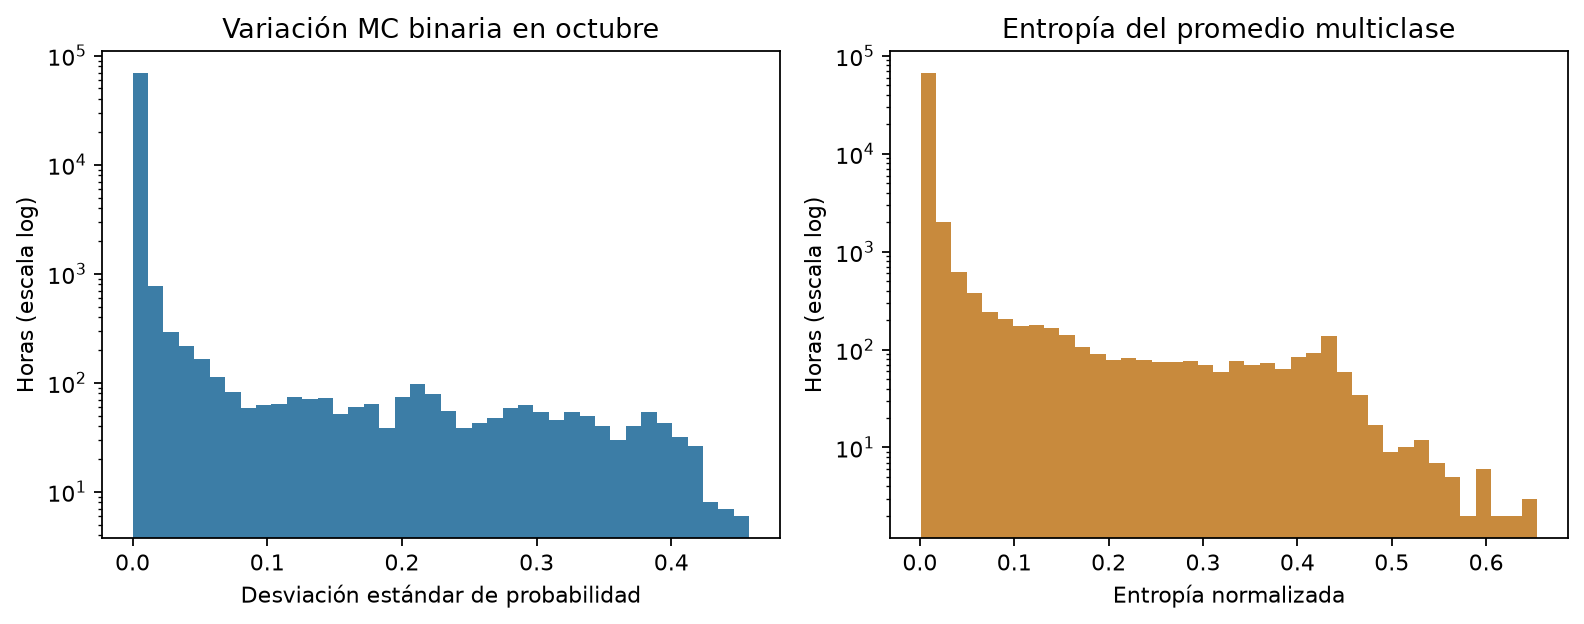

/var/folders/m0/9hmx0jw1693068pfqrhn3_3c0000gn/T/ipykernel_36364/358480367.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ejemplos_inciertos_11.round(6))


,machineID,datetime,etiqueta_multiclase,probabilidad_media_falla,DE_MC
35783,25,2015-10-21 23:00:00,ninguno,0.528959,0.457794
66195,46,2015-10-29 03:00:00,ninguno,0.529062,0.451979
38695,27,2015-10-23 07:00:00,ninguno,0.574249,0.450458
15596,11,2015-10-20 20:00:00,ninguno,0.610629,0.450415
3603,3,2015-10-01 03:00:00,ninguno,0.412571,0.447618
90463,63,2015-10-20 07:00:00,ninguno,0.622259,0.447078
38694,27,2015-10-23 06:00:00,ninguno,0.405872,0.444186
130460,91,2015-10-06 20:00:00,ninguno,0.603182,0.443049
80194,56,2015-10-12 10:00:00,ninguno,0.530240,0.442331
74503,52,2015-10-15 07:00:00,ninguno,0.420564,0.441836


In [5]:
indice_octubre_11 = np.flatnonzero(mascara_comprobacion_11)
entropia_multi_11 = -(media_mc_multi_11 * np.log(np.clip(media_mc_multi_11, 1e-12, 1))).sum(axis=1) / np.log(5)
max_desv_multi_11 = desv_mc_multi_11.max(axis=1)
resumen_incertidumbre_11 = []
for nombre, valores in [("DE probabilidad binaria", desv_mc_bin_11),
                         ("Mayor DE entre cinco clases", max_desv_multi_11),
                         ("Entropía multiclase normalizada", entropia_multi_11)]:
    octubre = valores[mascara_comprobacion_11]
    resumen_incertidumbre_11.append({"medida": nombre, "media": octubre.mean(),
                                    "mediana": np.median(octubre), "percentil_95": np.quantile(octubre, .95)})
display(pd.DataFrame(resumen_incertidumbre_11).round(6))
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].hist(desv_mc_bin_11[mascara_comprobacion_11], bins=40, log=True, color="#3c7da6")
ejes[0].set(title="Variación MC binaria en octubre", xlabel="Desviación estándar de probabilidad", ylabel="Horas (escala log)")
ejes[1].hist(entropia_multi_11[mascara_comprobacion_11], bins=40, log=True, color="#c88a3d")
ejes[1].set(title="Entropía del promedio multiclase", xlabel="Entropía normalizada", ylabel="Horas (escala log)")
fig.tight_layout()
plt.show()

# Mostrar diez horas con mayor dispersión, sin convertirlas en recomendaciones de intervención.
orden_inciertas_11 = indice_octubre_11[np.argsort(desv_mc_bin_11[indice_octubre_11])[-10:][::-1]]
ejemplos_inciertos_11 = anclas_11.loc[orden_inciertas_11, ["machineID", "datetime", "etiqueta_multiclase"]].copy()
ejemplos_inciertos_11["probabilidad_media_falla"] = media_mc_bin_11[orden_inciertas_11]
ejemplos_inciertos_11["DE_MC"] = desv_mc_bin_11[orden_inciertas_11]
display(ejemplos_inciertos_11.round(6))

En octubre, la desviación estándar binaria tuvo mediana **0.000562** y percentil 95 **0.009244**. La mayor desviación entre las cinco clases tuvo mediana **0.001273**; la entropía multiclase normalizada, mediana **0.004827**.

La tabla de diez horas muestra ejemplos de dispersión alta, sin afirmar que sean las únicas equivocaciones ni recomendar intervenir. Las horas cercanas pueden pertenecer al mismo episodio. La baja dispersión de otras horas tampoco certifica que sus probabilidades estén calibradas.

## 7. Ajustar temperatura únicamente con septiembre

Temperature scaling divide los logits por un número positivo `T` antes de convertirlos en probabilidades. Con `T = 1` no hay cambio; valores mayores suavizan las salidas y menores las hacen más extremas. Se basa en [Guo et al., On Calibration of Modern Neural Networks](https://arxiv.org/abs/1706.04599).

Ajustamos una temperatura binaria y otra multiclase para cada forma de inferencia: habitual y MC. En MC dividimos **cada muestra de logits** por `T`, convertimos y promediamos sus probabilidades. El ajuste usa exactamente esa misma mezcla, no la probabilidad obtenida a partir del logit promedio.

**Regla declarada:** minimizar log loss sin pesos de clase usando solo las 69,600 horas de ajuste. Buscamos `T` entre 0.05 y 20, con un máximo de 60 evaluaciones del optimizador por temperatura. Adoptamos la propuesta solo si reduce log loss de ajuste en más de 0.0001; en otro caso conservamos `T = 1`. Octubre no decide qué temperatura se adopta. Esta es una regla práctica, no una prueba estadística de necesidad.

No se actualizan las capas ni las normalizaciones. Temperatura no crea nuevas señales y no garantiza mejorar Brier o la comprobación posterior, porque se ajusta otro criterio. Tampoco se reutilizará automáticamente el umbral del paso 10: la política económica se definirá después.

Las funciones siguientes trabajan en logaritmos para evitar desbordamientos o probabilidades redondeadas a cero durante el ajuste.

In [6]:
def log_loss_temperatura_11(logits, y, temperatura, tarea):
    """Log loss estable de la mezcla de probabilidades; la primera dimensión son muestras."""
    escalados = logits / temperatura
    numero_muestras = logits.shape[0]
    if tarea == "binaria":
        log_positiva = -np.logaddexp(0, -escalados)
        log_negativa = -np.logaddexp(0, escalados)
        media_log_pos = logsumexp(log_positiva, axis=0) - np.log(numero_muestras)
        media_log_neg = logsumexp(log_negativa, axis=0) - np.log(numero_muestras)
        return float(-np.where(y == 1, media_log_pos, media_log_neg).mean())
    log_probabilidades = escalados - logsumexp(escalados, axis=2, keepdims=True)
    log_media = logsumexp(log_probabilidades, axis=0) - np.log(numero_muestras)
    return float(-log_media[np.arange(len(y)), y].mean())


def probabilidades_temperatura_11(logits, temperatura, tarea):
    """Promediar probabilidades después de escalar cada muestra de logits."""
    if tarea == "binaria":
        return expit(logits / temperatura).mean(axis=0)
    return softmax(logits / temperatura, axis=2).mean(axis=0)


def ajustar_temperatura_11(logits, y, tarea):
    """Ajustar solo con los argumentos de septiembre, sin consultar octubre."""
    datos = logits.astype(np.float64)
    inicial = log_loss_temperatura_11(datos, y, 1.0, tarea)
    def objetivo(log_temperatura):
        return log_loss_temperatura_11(datos, y, float(np.exp(log_temperatura)), tarea)
    ajuste = minimize_scalar(objetivo, bounds=(np.log(.05), np.log(20)), method="bounded",
                             options={"maxiter": 60, "xatol": .0001})
    assert ajuste.success
    propuesta = float(np.exp(ajuste.x))
    propuesta_loss = objetivo(ajuste.x)
    adoptar = inicial - propuesta_loss > .0001
    temperatura = propuesta if adoptar else 1.0
    return {"T_propuesta": propuesta, "T_adoptada": temperatura,
            "log_loss_inicial": inicial,
            "log_loss_adoptada": log_loss_temperatura_11(datos, y, temperatura, tarea),
            "adoptada": adoptar, "evaluaciones_optimizador": int(ajuste.nfev)}


# Comprobar T=1 y la mezcla con ejemplos conocidos antes del ajuste real.
z_bin = np.array([[-2., 2., .4], [-1., 1., -.2]])
y_b = np.array([0, 1, 1])
assert np.allclose(probabilidades_temperatura_11(z_bin, 1, "binaria"), expit(z_bin).mean(axis=0))
assert np.isclose(log_loss_temperatura_11(z_bin, y_b, 1, "binaria"), log_loss(y_b, expit(z_bin).mean(axis=0), labels=[0, 1]))
z_multi = np.array([[[2., 0., -1.], [0., 2., -1.]], [[1., 0., -1.], [0., 1., -1.]]])
y_m = np.array([0, 1])
assert np.isclose(log_loss_temperatura_11(z_multi, y_m, 1, "multiclase"),
                  log_loss(y_m, softmax(z_multi, axis=2).mean(axis=0), labels=[0, 1, 2]))
print("T=1 y log loss de las mezclas: verificados.")

logits_por_metodo_11 = {
    "Habitual": {"binaria": logits_habitual_bin_11, "multiclase": logits_habitual_multi_11},
    "MC Dropout": {"binaria": logits_mc_bin_11, "multiclase": logits_mc_multi_11},
}
ajustes_temperatura_11 = {}
filas_temperaturas_11 = []
for metodo, tareas in logits_por_metodo_11.items():
    ajustes_temperatura_11[metodo] = {}
    for tarea, logits in tareas.items():
        y = y_bin_11 if tarea == "binaria" else y_multi_11
        ajuste = ajustar_temperatura_11(logits[:, mascara_ajuste_11], y[mascara_ajuste_11], tarea)
        ajustes_temperatura_11[metodo][tarea] = ajuste
        filas_temperaturas_11.append({"método": metodo, "tarea": tarea, **ajuste})
        print("Temperatura ajustada:", metodo, tarea, flush=True)
tabla_temperaturas_11 = pd.DataFrame(filas_temperaturas_11)
display(tabla_temperaturas_11.round(6))

T=1 y log loss de las mezclas: verificados.
Temperatura ajustada: Habitual binaria
Temperatura ajustada: Habitual multiclase
Temperatura ajustada: MC Dropout binaria
Temperatura ajustada: MC Dropout multiclase


,método,tarea,T_propuesta,T_adoptada,log_loss_inicial,log_loss_adoptada,adoptada,evaluaciones_optimizador
0,Habitual,binaria,1.340416,1.340416,0.015408,0.013528,True,13
1,Habitual,multiclase,1.272982,1.272982,0.024284,0.021863,True,14
2,MC Dropout,binaria,0.922486,1.000000,0.010549,0.010549,False,15
3,MC Dropout,multiclase,0.882158,0.882158,0.016346,0.016084,True,14


Las decisiones se tomaron únicamente con septiembre:

- **Habitual — binaria:** T adoptada **1.3404**; log loss de ajuste **0.015408 → 0.013528**; se adoptó la propuesta.
- **Habitual — multiclase:** T adoptada **1.2730**; log loss de ajuste **0.024284 → 0.021863**; se adoptó la propuesta.
- **MC Dropout — binaria:** T adoptada **1.0000**; log loss de ajuste **0.010549 → 0.010549**; se conservó T = 1.
- **MC Dropout — multiclase:** T adoptada **0.8822**; log loss de ajuste **0.016346 → 0.016084**; se adoptó la propuesta.

La mejora de ajuste no implica que todo mejore en octubre. La temperatura se aplicó a cada muestra antes de promediar probabilidades en MC; se optimizó la log loss de esa misma mezcla. No se ajustaron pesos de clase ni parámetros de la red y no se utilizó prueba.

En MC binaria, la propuesta fue **T = 0.9225**, pero redujo la log loss de ajuste solo en **0.000055**, menos que el mínimo declarado de **0.0001**. Por eso conservar T = 1 fue una decisión de la regla, no una omisión.

## 8. Comprobar Brier y log loss en octubre

Comparamos cuatro versiones: habitual y MC, cada una sin temperatura y con la propuesta adoptada en septiembre. No volvemos a elegir según octubre.

El **Brier binario** es el promedio de `(p − y)^2`. El **Brier multiclase** es el promedio de la suma de los cinco errores cuadrados respecto a la clase real en one-hot. Usamos esa suma, no la dividimos entre cinco; por eso las dos tareas tienen escalas distintas. En ambos, menor es mejor.

Log loss penaliza probabilidades incorrectas muy confiadas. La calculamos sin pesos de clase y con las mismas funciones estables del ajuste. ECE es un resumen adicional en diez intervalos fijos; depende del agrupamiento y puede ocultar errores en clases raras. Ninguna de estas métricas sustituye la evaluación final en prueba.

In [7]:
def tabla_confiabilidad_11(probabilidades, reales, intervalos=10):
    """Frecuencia real y probabilidad media por intervalo; los vacíos no son datos faltantes."""
    grupos = np.minimum((probabilidades * intervalos).astype(int), intervalos - 1)
    filas = []
    for grupo in range(intervalos):
        seleccion = grupos == grupo
        cantidad = int(seleccion.sum())
        filas.append({"intervalo": grupo, "horas": cantidad,
                      "probabilidad_media": probabilidades[seleccion].mean() if cantidad else np.nan,
                      "frecuencia_real": reales[seleccion].mean() if cantidad else np.nan})
    return pd.DataFrame(filas)


def ece_11(probabilidades, reales):
    tabla = tabla_confiabilidad_11(probabilidades, reales)
    return float((tabla["horas"] / len(reales) * (tabla["probabilidad_media"] - tabla["frecuencia_real"]).abs()).sum())


versiones_11 = {}
filas_metricas_11 = []
for metodo, tareas in logits_por_metodo_11.items():
    for calibrada in [False, True]:
        tb = ajustes_temperatura_11[metodo]["binaria"]["T_adoptada"] if calibrada else 1.0
        tm = ajustes_temperatura_11[metodo]["multiclase"]["T_adoptada"] if calibrada else 1.0
        p_bin = probabilidades_temperatura_11(tareas["binaria"], tb, "binaria")
        p_multi = probabilidades_temperatura_11(tareas["multiclase"], tm, "multiclase")
        assert np.isfinite(p_bin).all() and np.isfinite(p_multi).all()
        assert np.allclose(p_multi.sum(axis=1), 1, atol=.00001)
        nombre = metodo + (" + temperatura" if calibrada else " sin temperatura")
        versiones_11[nombre] = {"binaria": p_bin, "multiclase": p_multi}
        p = p_bin[mascara_comprobacion_11]
        pm = p_multi[mascara_comprobacion_11]
        yb = y_bin_11[mascara_comprobacion_11]
        ym = y_multi_11[mascara_comprobacion_11]
        one_hot = np.eye(5)[ym]
        filas_metricas_11.append({"versión": nombre, "horas": len(yb),
            "Brier_binario": brier_score_loss(yb, p),
            "log_loss_binaria": log_loss_temperatura_11(tareas["binaria"][:, mascara_comprobacion_11].astype(np.float64), yb, tb, "binaria"),
            "ECE_binario": ece_11(p, yb),
            "Brier_multiclase": np.mean(np.sum((pm - one_hot) ** 2, axis=1)),
            "log_loss_multiclase": log_loss_temperatura_11(tareas["multiclase"][:, mascara_comprobacion_11].astype(np.float64), ym, tm, "multiclase")})
metricas_calibracion_11 = pd.DataFrame(filas_metricas_11)
display(metricas_calibracion_11.round(6))
assert all(torch.equal(valor, estado_inicial_11[nombre]) for nombre, valor in modelo_11.state_dict().items())
print("Comprobación realizada únicamente con octubre; el modelo conserva sus pesos.")

,versión,horas,Brier_binario,log_loss_binaria,ECE_binario,Brier_multiclase,log_loss_multiclase
0,Habitual sin temperatura,72000,0.002765,0.010962,0.003956,0.008941,0.019831
1,Habitual + temperatura,72000,0.002656,0.010468,0.005241,0.008618,0.018640
2,MC Dropout sin temperatura,72000,0.002219,0.008687,0.005274,0.007036,0.014203
3,MC Dropout + temperatura,72000,0.002219,0.008687,0.005274,0.007007,0.013637


Comprobación realizada únicamente con octubre; el modelo conserva sus pesos.


Resultados en las **72,000 horas de octubre**:

- **Habitual:** Brier binario **0.002765 → 0.002656** (bajó); Brier multiclase **0.008941 → 0.008618**. Log loss binaria **0.010962 → 0.010468** y multiclase **0.019831 → 0.018640**.
- **MC Dropout:** Brier binario **0.002219 → 0.002219** (se mantuvo); Brier multiclase **0.007036 → 0.007007**. Log loss binaria **0.008687 → 0.008687** y multiclase **0.014203 → 0.013637**.

Estas comparaciones no cambian las temperaturas elegidas con septiembre. Brier y log loss describen aspectos relacionados, pero el ajuste minimiza log loss, no todas las métricas a la vez. Además, los puntajes globales pueden estar dominados por horas sanas; no equivalen a buen desempeño en todos los componentes.

En la salida habitual, ECE binario **aumentó de 0.003956 a 0.005241**, aunque Brier y log loss mejoraron. No se afirma que temperatura mejore todas las medidas. En la binaria MC se conservó T = 1, por lo que sus cifras antes y después coinciden; esa igualdad es esperada.

## 9. Diagramas de confiabilidad

En la tarea binaria, un grupo con probabilidad media 0.20 debería tener una frecuencia de positivos cercana a 0.20. La diagonal representa esa coincidencia. Mostramos por separado habitual y MC, antes y después de temperatura.

Para multiclase, la confiabilidad superior compara la probabilidad de la clase elegida con la frecuencia de aciertos de esa clase elegida. No es un diagrama individual de cada componente; por eso también conservamos Brier y log loss de las cinco probabilidades.

Los intervalos con pocas horas son más inestables. Las curvas se acompañan de una tabla de cantidades; no se añaden intervalos de confianza suponiendo independencia entre ventanas solapadas.

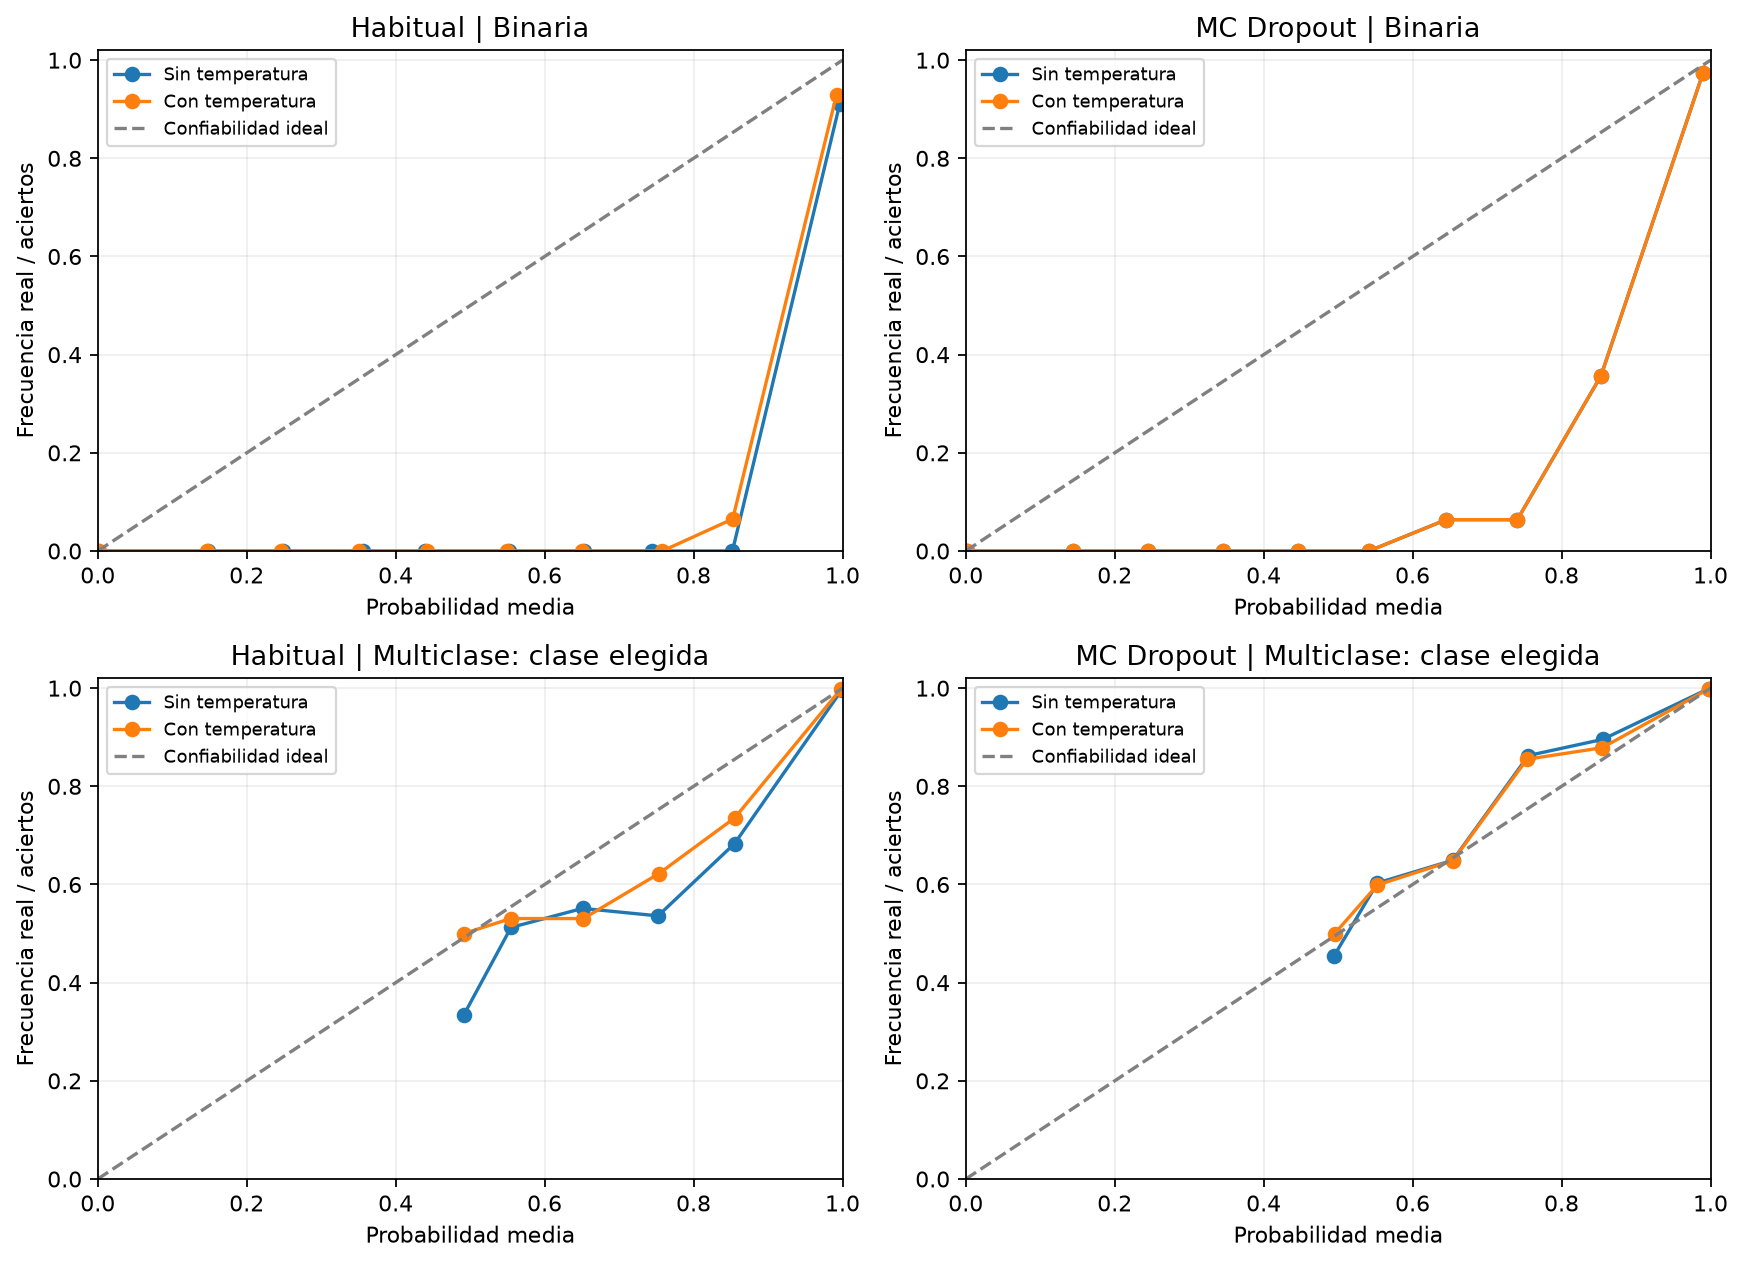

versión,Habitual + temperatura,Habitual sin temperatura,MC Dropout + temperatura,MC Dropout sin temperatura
intervalo,,,,
0,70169,70252,69823,69823
1,117,84,328,328
2,75,53,162,162
3,51,37,109,109
4,46,32,74,74
5,38,31,58,58
6,32,23,47,47
7,35,25,47,47
8,46,40,42,42


In [8]:
filas_intervalos_11 = []
fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
for columna, metodo in enumerate(["Habitual", "MC Dropout"]):
    for calibrada, etiqueta in [(False, "Sin temperatura"), (True, "Con temperatura")]:
        nombre = metodo + (" + temperatura" if calibrada else " sin temperatura")
        version = versiones_11[nombre]
        p = version["binaria"][mascara_comprobacion_11]
        pm = version["multiclase"][mascara_comprobacion_11]
        yb = y_bin_11[mascara_comprobacion_11]
        ym = y_multi_11[mascara_comprobacion_11]
        binaria = tabla_confiabilidad_11(p, yb)
        elegida = pm.argmax(axis=1)
        superior = tabla_confiabilidad_11(pm.max(axis=1), (elegida == ym).astype(int))
        ejes[0, columna].plot(binaria["probabilidad_media"], binaria["frecuencia_real"], marker="o", label=etiqueta)
        ejes[1, columna].plot(superior["probabilidad_media"], superior["frecuencia_real"], marker="o", label=etiqueta)
        conteos = binaria[["intervalo", "horas"]].copy()
        conteos.insert(0, "versión", nombre)
        filas_intervalos_11.append(conteos)
    for fila, tarea in [(0, "Binaria"), (1, "Multiclase: clase elegida")]:
        eje = ejes[fila, columna]
        eje.plot([0, 1], [0, 1], "--", color="gray", label="Confiabilidad ideal")
        eje.set(title=metodo + " | " + tarea, xlabel="Probabilidad media", ylabel="Frecuencia real / aciertos", xlim=(0, 1), ylim=(0, 1.02))
        eje.legend(fontsize=8)
        eje.grid(alpha=.2)
fig.tight_layout()
plt.show()
conteos_intervalos_11 = pd.concat(filas_intervalos_11, ignore_index=True)
display(conteos_intervalos_11.pivot(index="intervalo", columns="versión", values="horas"))

Las curvas corresponden solo a octubre y usan los mismos diez intervalos de probabilidad para cada versión. La tabla registra cuántas horas sostienen cada punto. Los tamaños son muy desiguales: el intervalo más pequeño contiene **23 horas**, mientras algunos concentran más de **69,000**. La estabilidad de sus frecuencias no es la misma, aunque no haya grupos con menos de diez horas.

La diagonal es una referencia, no un ajuste adicional. En la tarea multiclase se resume la confianza de la clase elegida y puede predominar `ninguno`; no se concluye que cada componente esté igualmente calibrado. Los intervalos vacíos no indican valores faltantes en los sensores.

En la binaria, varios puntos intermedios están por debajo de la diagonal: esas probabilidades sobreestiman la frecuencia de falla observada en sus grupos. Los puntajes globales pequeños no eliminan ese problema local. En MC binaria las dos curvas se superponen porque no se adoptó otra temperatura; no son dos ajustes independientes que casualmente dieron igual.

## 10. Qué queda listo y límites

Quedan en memoria las muestras MC, las temperaturas adoptadas en septiembre, las probabilidades y los diagnósticos de octubre. El modelo conserva sus pesos y las transformaciones originales. Los números y gráficas se guardan como salidas visibles dentro del notebook; no se exportan modelos, figuras o CSV de métricas.

Se completó el apartado 3.2 con MC Dropout, medidas de dispersión y entropía, Brier de ambas tareas y diagramas de confiabilidad. De las cuatro propuestas de temperatura, **3** se adoptaron según la mejora mínima de log loss en septiembre, antes de comprobar octubre.

La comprobación muestra cómo se comportan las probabilidades fuera del bloque de ajuste de temperatura, sin convertirlas en una política de intervención. Se conservaron las mismas filas y transformaciones originales; el margen interno evita que las etiquetas de ajuste requieran eventos de octubre. Esto no borra el uso previo de todo el periodo de validación para elegir épocas y modelos.

Este estudio no elige todavía una política ni un modelo final. Octubre ya participó en decisiones anteriores y sus resultados siguen siendo de desarrollo. MC Dropout no garantiza detectar todas las equivocaciones; temperature scaling no garantiza mejorar todas las métricas ni corrige por sí solo el componente predicho. Prueba continúa reservada para una sola evaluación al final, con las decisiones ya fijadas.